continent  countries  mean_life_expectancy  mean_deviation
   Africa         52                 54.81          -12.20
     Asia         33                 70.73            3.72
 Americas         25                 73.61            6.60
   Europe         30                 77.65           10.64
  Oceania          2                 80.72           13.71

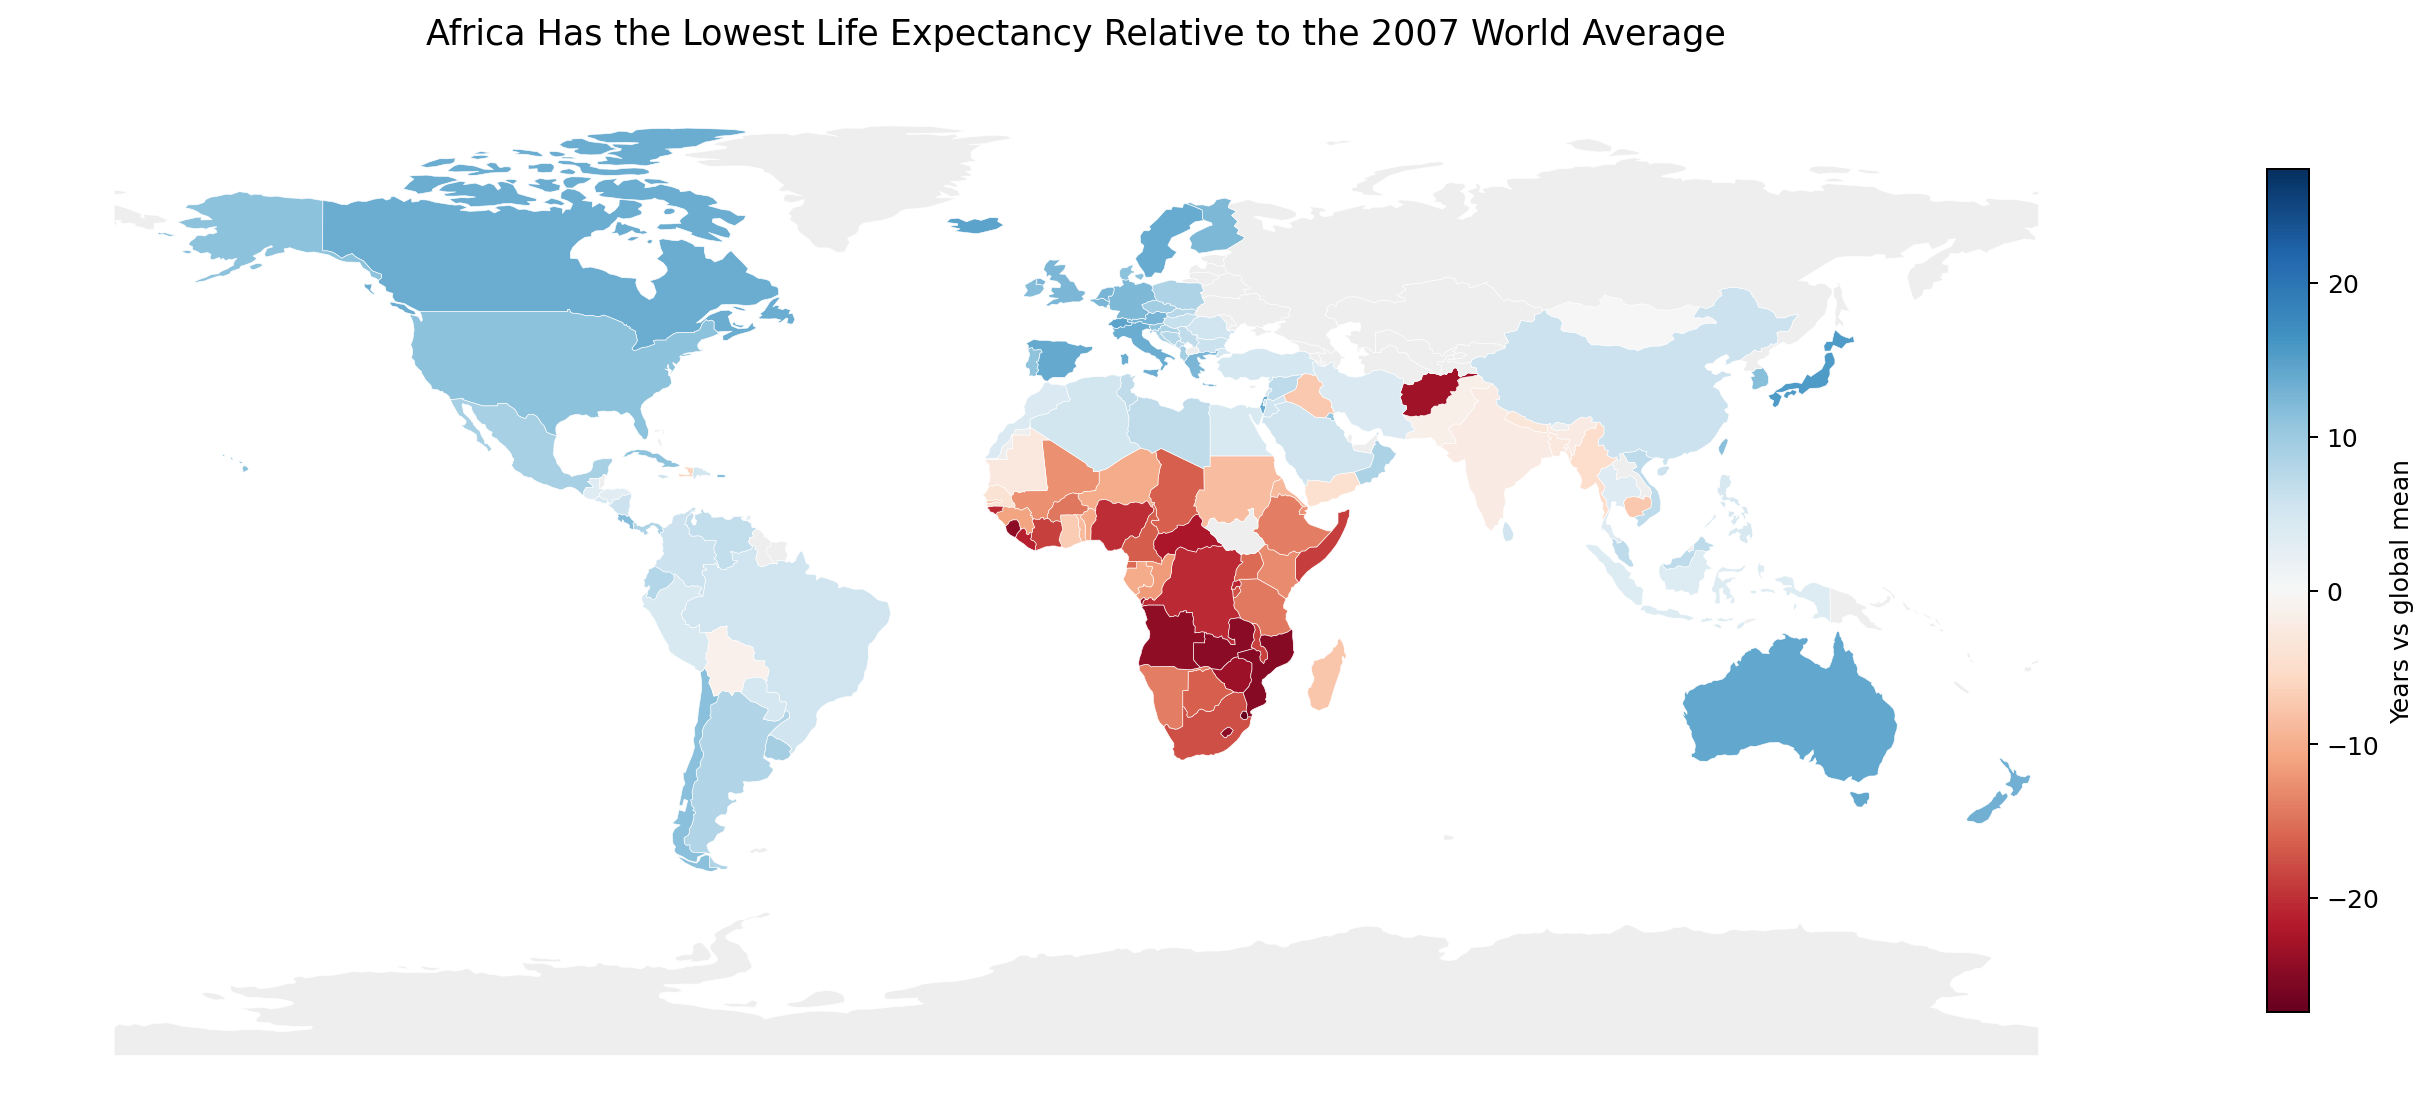

In [ ]:
import pandas as pd
import plotly.express as px
from pathlib import Path
from IPython.display import display, Image

gm = px.data.gapminder()
gm_2007 = gm[gm["year"] == 2007].copy()

global_mean = gm_2007["lifeExp"].mean()
gm_2007["lifeExp_deviation"] = gm_2007["lifeExp"] - global_mean

continent_summary = (
    gm_2007.groupby("continent")
    .agg(
        countries=("country", "count"),
        mean_life_expectancy=("lifeExp", "mean"),
        mean_deviation=("lifeExp_deviation", "mean")
    )
    .round(2)
    .sort_values("mean_deviation")
    .reset_index()
)

lowest_continent = continent_summary.iloc[0]["continent"]

# px.choropleth is used because the comparison is country-level and does not require map tiles.
# RdBu is a diverging scale centred at zero because deviations can be above or below the world mean.
fig1 = px.choropleth(
    gm_2007,
    locations="iso_alpha",
    locationmode="ISO-3",
    color="lifeExp_deviation",
    color_continuous_scale="RdBu",
    color_continuous_midpoint=0,
    hover_name="country",
    hover_data={
        "lifeExp": ":.1f",
        "lifeExp_deviation": ":+.1f",
        "iso_alpha": False
    },
    labels={
        "lifeExp": "Life expectancy (years)",
        "lifeExp_deviation": "Deviation from global mean (years)"
    },
    title=f"{lowest_continent} Has the Lowest Life Expectancy Relative to the 2007 World Average",
    height=620
)

fig1.update_layout(
    title_x=0.5,
    title_font_size=17,
    geo=dict(showframe=False),
    margin=dict(l=10, r=10, t=95, b=10),
    coloraxis_colorbar=dict(title="Years vs global mean")
)

display(continent_summary)

figures_dir = Path("../figures")
figures_dir.mkdir(parents=True, exist_ok=True)

fig1.write_html(
    figures_dir / "task1_world_interactive.html",
    include_plotlyjs=True,
    full_html=True
)

display(Image(filename=str(figures_dir / "task1_world_choropleth.png")))
fig1.show()


                district  population
                  Pankow      415221
                   Mitte      384172
  Tempelhof - Schöneberg      351622
    Charlottenburg-Wilm.      343276
                Neukölln      335335
   Steglitz - Zehlendorf      308706
Friedrichshain-Kreuzberg      295864
             Lichtenberg      295386
      Treptow - Köpenick      272843
   Marzahn - Hellersdorf      271038
           Reinickendorf      265755
                 Spandau      245197

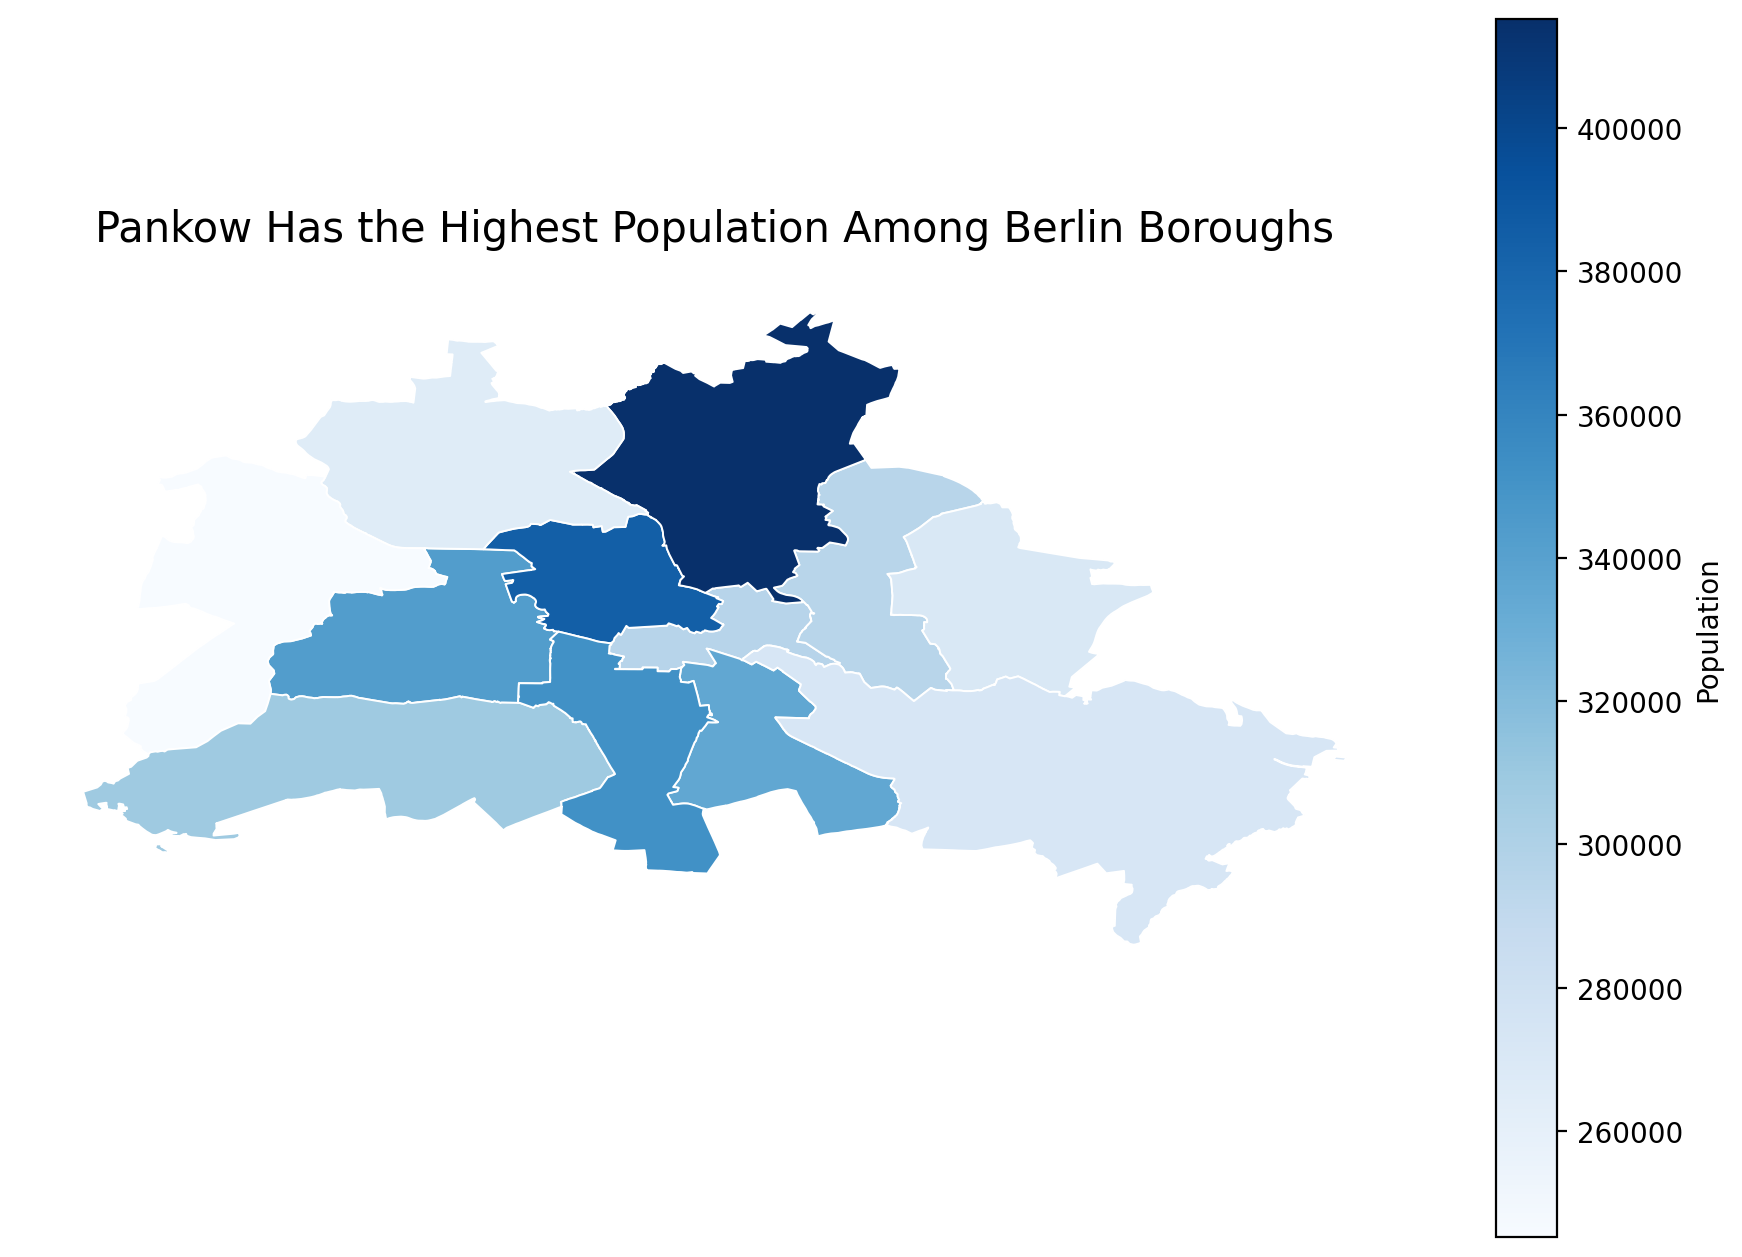

In [ ]:
import pandas as pd
import plotly.express as px
import json
from pathlib import Path
from IPython.display import display, Image

berlin_population = pd.DataFrame({
    "district": [
        "Charlottenburg-Wilm.",
        "Friedrichshain-Kreuzberg",
        "Pankow",
        "Spandau",
        "Steglitz - Zehlendorf",
        "Tempelhof - Schöneberg",
        "Neukölln",
        "Treptow - Köpenick",
        "Marzahn - Hellersdorf",
        "Lichtenberg",
        "Reinickendorf",
        "Mitte"
    ],
    "population": [
        343276, 295864, 415221, 245197,
        308706, 351622, 335335, 272843,
        271038, 295386, 265755, 384172
    ]
})

geojson_path = Path("../data/neighbourhoods-13.geojson")
with open(geojson_path, "r", encoding="utf-8") as file:
    berlin_geojson = json.load(file)

# Inspecting the GeoJSON confirms that the borough identifier is neighbourhood_group.
print(berlin_geojson["features"][0]["properties"])

berlin_geojson["features"] = [
    feature for feature in berlin_geojson["features"]
    if feature["properties"].get("neighbourhood_group")
]

# px.choropleth is used because borough boundaries are already supplied as GeoJSON and no basemap tiles are needed.
# Blues is a sequential scale because population is non-negative and higher values represent more people.
fig2 = px.choropleth(
    berlin_population,
    geojson=berlin_geojson,
    locations="district",
    featureidkey="properties.neighbourhood_group",
    color="population",
    color_continuous_scale="Blues",
    hover_name="district",
    hover_data={"population": ":,"},
    title="Pankow Has the Highest Population Among Berlin Boroughs",
    height=680
)

fig2.update_geos(fitbounds="locations", visible=False)
fig2.update_layout(
    title_x=0.5,
    title_font_size=19,
    coloraxis_colorbar_title="Population",
    margin={"r": 0, "t": 70, "l": 0, "b": 0}
)

display(
    berlin_population.sort_values(
        "population", ascending=False
    ).reset_index(drop=True)
)

figures_dir = Path("../figures")
figures_dir.mkdir(parents=True, exist_ok=True)

fig2.write_html(
    figures_dir / "task2_berlin_interactive.html",
    include_plotlyjs=True,
    full_html=True
)

display(Image(filename=str(figures_dir / "task2_berlin_choropleth.png")))
fig2.show()
